# Income dataset

One row per person in `income/income_dataset.csv` (100,000 people). The label is `INCOME_AMOUNT_TOTAL`, declared monthly income in GEL.

Columns come from two places. The loan file (person, remittances, credit history, the loan applied for) keeps its original names. Open-banking aggregates from the 12-month API history are prefixed `ob_`.

`PTI_RATIO` is not in this file. It is the monthly payment divided by this income, so it contains the label.

100,000 rows, 111 columns, 100,000 distinct people
label INCOME_AMOUNT_TOTAL: 300 – 10000 GEL, mean 3340, median 2716, missing 0


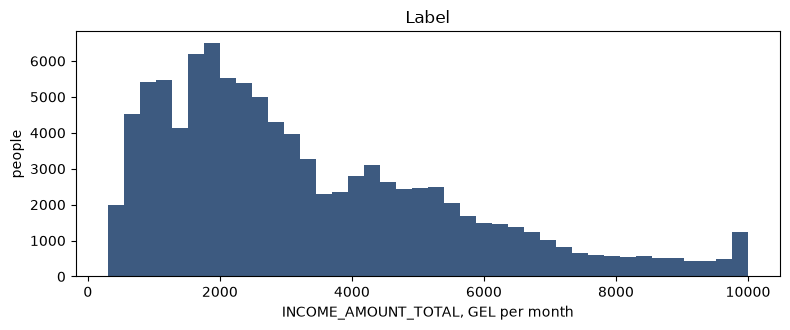

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

REPO = Path.cwd().resolve()
if not (REPO / "EDA.py").is_file():
    REPO = next(p for p in REPO.parents if (p / "EDA.py").is_file())
sys.path.insert(0, str(REPO))

from EDA import FAMILIES, FEATURES, MOCK_FEATURES

pd.set_option("display.max_rows", 200)
pd.set_option("display.max_colwidth", 140)
pd.set_option("display.width", 160)

df = pd.read_csv(REPO / "income" / "income_dataset.csv")
income = df["INCOME_AMOUNT_TOTAL"]
print(
    f"{len(df):,} rows, {df.shape[1]} columns, {df['cid'].nunique():,} distinct people"
)
print(
    f"label INCOME_AMOUNT_TOTAL: {income.min():.0f} – {income.max():.0f} GEL, "
    f"mean {income.mean():.0f}, median {income.median():.0f}, missing {int(income.isna().sum())}"
)

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.hist(income, bins=40, color="#3d5a80")
ax.set_xlabel("INCOME_AMOUNT_TOTAL, GEL per month")
ax.set_ylabel("people")
ax.set_title("Label")
fig.tight_layout()
plt.show()

## Features

Every column, in file order. `group` is the loan-file family from the variable dictionary, or the open-banking family. `min` / `median` / `max` are filled for numeric columns.

In [2]:
PERSON = {
    "segment": "Customer segment assigned by the simulator.",
    "region_name": "Region name. The loan file only stores the region code.",
    "city": "City.",
    "banks": "Banks this person is connected to, primary first, separated by |.",
}
OB = {name: (fam, desc) for name, fam, desc in MOCK_FEATURES}

rows = []
for col in df.columns:
    if col == "cid":
        group, kind, meaning = "id", "id", "Person id in the open-banking dataset, C00001 to C100000."
    elif col == "INCOME_AMOUNT_TOTAL":
        group, kind, meaning = "label", FEATURES[col][1], FEATURES[col][2] + " This is the label."
    elif col in PERSON:
        group, kind, meaning = "person", "text", PERSON[col]
    elif col in FEATURES:
        fam, kind, meaning = FEATURES[col]
        group = FAMILIES[fam][0]
        if col == "addNegStatus":
            group = "Negative-status flag"
            meaning = meaning + " Not the label of this file."
    elif col.startswith("ob_") and col.removeprefix("ob_") in OB:
        fam, meaning = OB[col.removeprefix("ob_")]
        group, kind = f"open banking · {fam}", "number"
    else:
        group, kind, meaning = "other", "", "not described"
    rows.append({"column": col, "group": group, "kind": kind, "meaning": meaning})

catalog = pd.DataFrame(rows)
num = df.select_dtypes("number")
catalog["missing"] = catalog["column"].map(df.isna().sum()).astype(int)
catalog["missing_pct"] = catalog["column"].map((df.isna().mean() * 100).round(2))
catalog["distinct"] = catalog["column"].map(lambda c: int(df[c].nunique(dropna=True)))
catalog["min"] = catalog["column"].map(num.min()).round(4)
catalog["median"] = catalog["column"].map(num.median()).round(4)
catalog["max"] = catalog["column"].map(num.max()).round(4)

undescribed = catalog.loc[catalog["group"] == "other", "column"].tolist()
print(f"{len(catalog)} columns. Not described: {undescribed or 'none'}")
print(catalog.groupby("group", sort=False).size().rename("columns").to_string())
display(catalog)

111 columns. Not described: none
group
id                                   1
label                                1
person                               4
Customer profile                     6
Income                               1
Loan terms & product                14
Instalment schedule                  4
Affordability & collateral           2
Delinquency & penalties             14
Balances & term-to-go                4
Loan events                          2
Credit-bureau inquiries              4
Borrower's other contracts           2
Supplied score / PD                  2
Negative-status flag                 1
open banking · footprint             7
open banking · cash flow             9
open banking · income                6
open banking · spending              8
open banking · debt signals          6
open banking · balance               5
open banking · loan seen via API     8


,column,group,kind,meaning,missing,missing_pct,distinct,min,median,max
0,cid,id,id,"Person id in the open-banking dataset, C00001 to C100000.",0,0.00,100000,NaN,NaN,NaN
1,INCOME_AMOUNT_TOTAL,label,amount,"Income amount (total); period, currency and gross/net are not stated This is the label.",0,0.00,99171,300.0000,2716.4370,10000.0000
2,segment,person,text,Customer segment assigned by the simulator.,0,0.00,2,NaN,NaN,NaN
3,region_name,person,text,Region name. The loan file only stores the region code.,0,0.00,12,NaN,NaN,NaN
4,city,person,text,City.,0,0.00,24,NaN,NaN,NaN
5,banks,person,text,"Banks this person is connected to, primary first, separated by |.",0,0.00,458,NaN,NaN,NaN
6,CLIENT_GEOGRAPHICAL_REGION,Customer profile,nominal,Client's region code (1-12; name mapping not provided),0,0.00,12,1.0000,3.0000,12.0000
7,CLIENT_LEGAL_FORM,Customer profile,nominal,"Client legal form (1 = sole proprietor, 7 = private individual; see lookup)",0,0.00,2,1.0000,7.0000,7.0000
8,SEX,Customer profile,binary,Sex code (1 / 2; mapping not provided),0,0.00,2,1.0000,1.0000,2.0000
9,Age,Customer profile,count,Age in years,0,0.00,60,20.0000,41.0000,79.0000


## Nulls

97 columns are filled for every person. The 14 with blanks are open-banking fields. The last column is counted from the rows.

14 columns have nulls. The other 97 columns are complete.


,column,group,missing,missing_pct,meaning,blank when
0,ob_salary_month,open banking · income,5922,5.92,average salary credit (entries typed salary) in GEL; missing if none,no salary credit (100% of blanks have salary_months = 0)
1,ob_salary_cv,open banking · income,5922,5.92,coefficient of variation of the salary credits,no salary credit (100% of blanks have salary_months = 0)
2,ob_salary_day_std,open banking · income,5922,5.92,standard deviation of the booking day-of-month of the salary credits,no salary credit (100% of blanks have salary_months = 0)
3,ob_card_ticket,open banking · spending,2,0.00,average card purchase in GEL,no card purchase (100% of blanks have card_spend_month = 0)
4,ob_bal_min_ratio,open banking · balance,1579,1.58,"lowest running balance after any entry / monthly inflow (current accounts, GEL)","transactions have no running balance (procredit 543, bog 376 of 1579)"
5,ob_bal_mean_ratio,open banking · balance,1579,1.58,"average running balance after an entry (entry-weighted, not time-weighted) / monthly inflow","transactions have no running balance (procredit 543, bog 376 of 1579)"
6,ob_bal_neg_share,open banking · balance,1579,1.58,share of entries after which the running balance is negative,"transactions have no running balance (procredit 543, bog 376 of 1579)"
7,ob_end_balance_ratio,open banking · balance,424,0.42,closing balance of the current accounts today / monthly inflow,no GEL closing balance on an account (100% of blanks are Paysera-primary)
8,ob_loan_rate_pct,open banking · loan seen via API,72342,72.34,interest rate of the visible loan (%),"no loan listed by the API for 97% of blanks; the rest have a loan listed, but this field is empty"
9,ob_loan_age_months,open banking · loan seen via API,72342,72.34,months since the visible loan's contract start,"no loan listed by the API for 97% of blanks; the rest have a loan listed, but this field is empty"


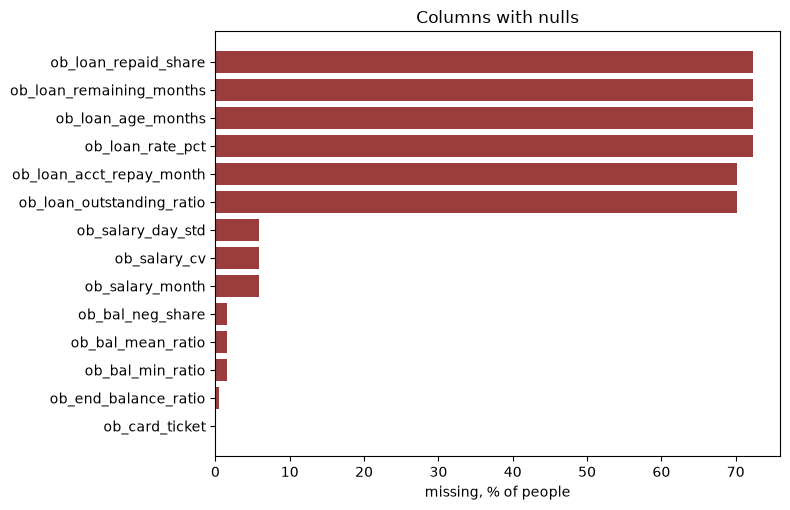

In [3]:
def blank_when(col: str) -> str:
    missing = df[col].isna()
    if not missing.any():
        return ""
    if col.startswith("ob_salary_"):
        share = (df.loc[missing, "ob_salary_months"] == 0).mean()
        return f"no salary credit ({share:.0%} of blanks have salary_months = 0)"
    if col == "ob_card_ticket":
        share = (df.loc[missing, "ob_card_spend_month"].fillna(0) == 0).mean()
        return f"no card purchase ({share:.0%} of blanks have card_spend_month = 0)"
    if col in {"ob_bal_min_ratio", "ob_bal_mean_ratio", "ob_bal_neg_share"}:
        primary = df.loc[missing, "banks"].str.split("|").str[0]
        top = ", ".join(f"{name} {n}" for name, n in primary.value_counts().head(2).items())
        return f"transactions have no running balance ({top} of {int(missing.sum())})"
    if col == "ob_end_balance_ratio":
        primary = df.loc[missing, "banks"].str.split("|").str[0]
        share = (primary == "paysera").mean()
        return f"no GEL closing balance on an account ({share:.0%} of blanks are Paysera-primary)"
    if col.startswith("ob_loan_") and col not in {"ob_loan_visible", "ob_loan_overdue_visible"}:
        share = (df.loc[missing, "ob_loan_visible"] == 0).mean()
        if share == 1:
            return "no loan listed by the API (100% of blanks have loan_visible = 0)"
        return (
            f"no loan listed by the API for {share:.0%} of blanks; "
            "the rest have a loan listed, but this field is empty"
        )
    return ""


nulls = catalog.loc[catalog["missing"] > 0, ["column", "group", "missing", "missing_pct", "meaning"]].copy()
nulls["blank when"] = nulls["column"].map(blank_when)
print(f"{len(nulls)} columns have nulls. The other {df.shape[1] - len(nulls)} columns are complete.")
display(nulls.reset_index(drop=True))

fig, ax = plt.subplots(figsize=(8, 5.2))
plot = nulls.sort_values("missing_pct")
ax.barh(plot["column"], plot["missing_pct"], color="#9b3d3d")
ax.set_xlabel("missing, % of people")
ax.set_title("Columns with nulls")
fig.tight_layout()
plt.show()